<a href="https://colab.research.google.com/github/Abivisu2/Pos-graduacao-Ciencia-de-dados/blob/main/Laborat%C3%B3rio_2_%E2%80%93_Visualiza%C3%A7%C3%A3o_de_Dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório 2 – Visualização de Dados[<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados/images/colag_logo.svg" style="float: right; margin-right: 0%; vertical-align: middle; width: 6.5%;">](https://colab.research.google.com/github/urielmoreirasilva/ICX532/blob/main/labs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados.ipynb) [<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados/images/github_logo.svg" style="float: right; margin-right: 0%; vertical-align: middle; width: 3.25%;">](https://github.com/urielmoreirasilva/ICX532/blob/main/labs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados.ipynb)

Bem-vindo ao Laboratório 2! Nesta tarefa, aprenderemos mais sobre `array`s, `DataFrame`s, criar visualizações de dados e como escrever funções em Python.

Você deve concluir todo este laboratório e enviá-lo ao Moodle até às 23h59 da data de vencimento.

### Referências
- [BPD: Capítulos 6, 7, 8. 9, 10, 11 e 12](https://notes.dsc10.com/)
- [CIT: Capítulo 6, 7 e 8](https://inferentialthinking.com/)
- Aulas: Tópicos 4, 5, 6 e 7.

Material adaptado do [DSC10 (UCSD)](https://dsc10.com/) por [Flavio Figueiredo (DCC-UFMG)](https://flaviovdf.io/fcd/) e [Uriel Silva (DEST-UFMG)](https://urielmoreirasilva.github.io)

**<u> NOTA</u>: Não use loops `for` em nenhuma pergunta deste laboratório.** Lembre do Tópico 08 que os loops em Python são lentos, e os loops em `arrays` e `DataFrame`s geralmente devem ser evitados. Como alternativa, devemos idealmente utilizar as funções nativas de bibliotecas como `numpy` e `pandas` para a manipulação desses objetos.

In [ ]:
## Imports para esse laboratório
import numpy as np
import pandas as pd

## Opções do MatplotLib
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Aplicativos da Google Play Store 📲

Neste problema, praticaremos manipulações de DataFrame e visualizações de dados com o [Google Play Store Apps Dataset](https://www.kaggle.com/lava18/google-play-store-apps), extraído da Google Play Store.

Começamos carregando o conjunto de dados de um arquivo `.csv` externo, utilizando o método `pd.csv()`:

In [ ]:
apps = pd.read_csv("https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados/data/googleplaystore.csv")
apps

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000.0,Free,0,Everyone,Art & Design
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,500000.0,Free,0,Everyone,Art & Design;Pretend Play
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000.0,Free,0,Everyone,Art & Design
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000.0,Free,0,Teen,Art & Design
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000.0,Free,0,Everyone,Art & Design;Creativity
...,...,...,...,...,...,...,...,...,...,...
10820,Sya9a Maroc - FR,FAMILY,4.5,38,53M,5000.0,Free,0,Everyone,Education
10821,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100.0,Free,0,Everyone,Education
10822,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,1000.0,Free,0,Everyone,Medical
10823,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,1000.0,Free,0,Mature 17+,Books & Reference


Cada linha no DataFrame `apps` acima corresponde à um aplicativo. Algumas das colunas nas quais estamos interessados aqui são:
- `'Category'`: Categoria à qual o aplicativo pertence;
- `'Rating'`: Avaliação geral do usuário do aplicativo, de 1 a 5 (no momento da recuperação de dados);
- `'Reviews'`: Número de avaliações do aplicativo (no momento da recuperação dos dados);
- `'Installs'`: Número de downloads/instalações do aplicativo (no momento da recuperação dos dados).
- `'Content Rating'`: Público-alvo do aplicativo.

*<u>Nota</u>: Observe que os conteúdos das colunas `'Rating'` e `'Content Rating'` são bem diferentes!*

Note que aqui não definimos o índice do DataFrame! Embora à primeira vista possa parecer que o nome do aplicativo (coluna `App`) seria um bom candidato para índice, os nomes dos aplicativos *não são exclusivos*!

Podemos verificar a não-exclusividade da coluna `App` através do método `.unique()`. Quando chamado em uma `Series`, este método retorna um `array` contendo todos os valores distintos da Series, sem duplicatas.

In [ ]:
len(apps)

10825

In [ ]:
len(apps.get('App').unique())

9644

Vemos na célula de código acima que o DataFrame `apps` possui 10.825 linhas, e logo isso significa que existem 10.825 aplicativos no conjunto de dados. Porém, ao utilizar o método `.unique()`, vemos que apenas 9.644 desses nomes de aplicativos são únicos, o que nos leva a concluir que devem existir nomes duplicados.

#### **Pergunta 1.1.**

É razoável pensar que, em uma escala de 1 a 5, um aplicativo "típico" deve ter uma classificação de aproximadamente 3.
Complete a célula de código abaixo com um histograma da coluna `'Rating'` para verificar esse raciocínio.

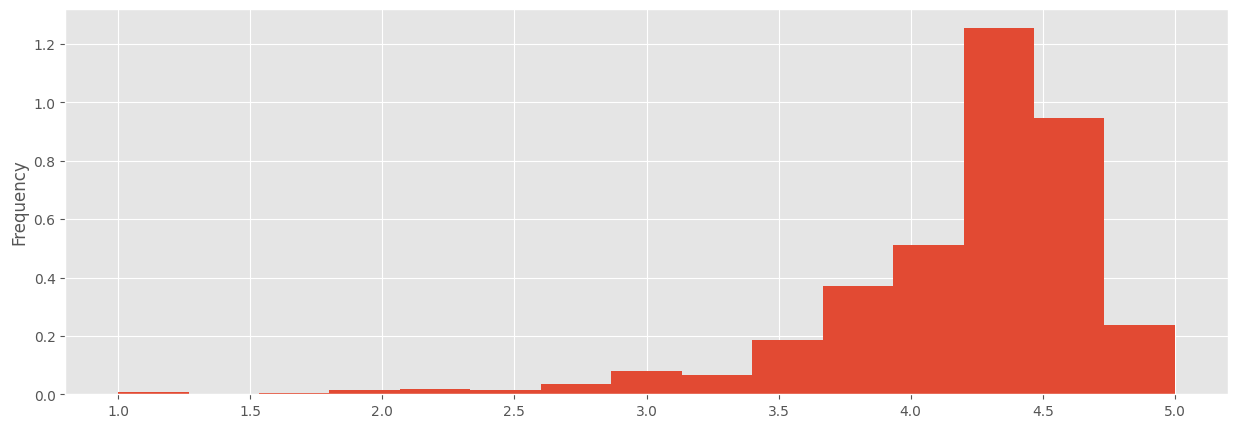

In [ ]:
# Descomente e execute!
apps.get('Rating').plot(
    kind = 'hist',
    density = True,
    ec = 'w',
    bins = 15,
    figsize = (15, 5));

Agora, uma pergunta natural ao analisar o histograma acima é: "será que os aplicativos com classificações mais altas também têm mais avaliações?"

#### **Pergunta 1.2.**

Que tipo de gráfico você gostaria de criar para ajudar a determinar se os aplicativos com classificação mais alta também têm mais avaliações? Preencha a célula de texto abaixo com a resposta.

**A.** Gráfico de dispersão

**B.** Gráfico de linha

**C.** Gráfico de barras

**D.** Histograma

>Gráfico de barras

#### **Pergunta 1.3.**

Na célula de código abaixo, crie o gráfico correspondente à sua resposta da pergunta acima para ajudá-lo a determinar se os aplicativos com classificação mais alta também são os que têm mais avaliações.

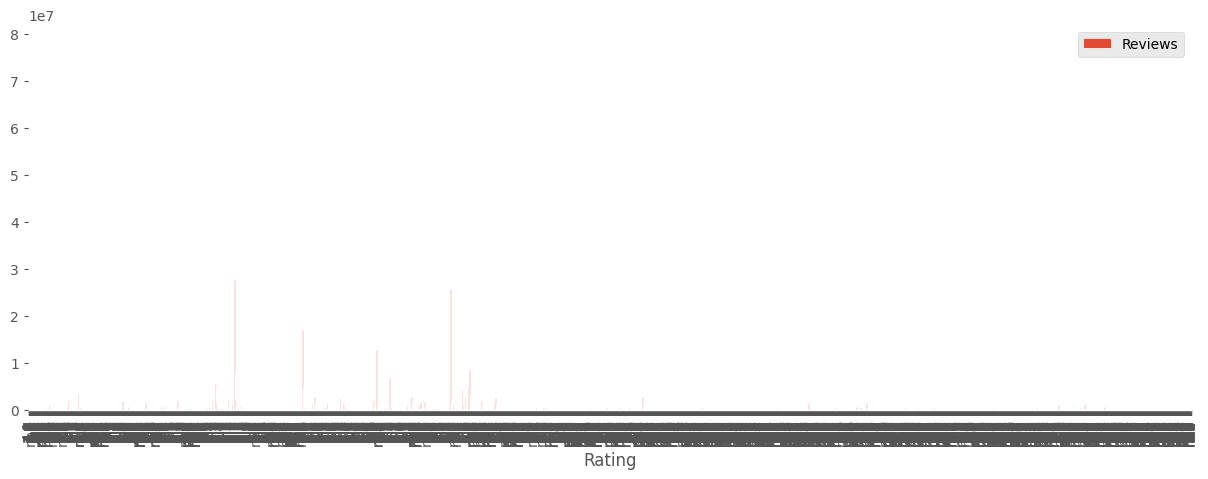

In [ ]:
# Descomente e execute!
apps.plot(
    kind = 'bar',
    x = 'Rating',
    y = 'Reviews',
    ec = 'w',
    figsize = (15, 5));

#### **Pergunta 1.4.**

Na célula de código abaixo, atribua ao objeto `by_content` um DataFrame contendo o número total de aplicativos em `apps`, organizados (ou "estratificados") por `'Content Rating'`.

*<u>Dica 1</u>: Utilize o método `.groupby()` e depois aplique o método `.count()`, agrupando pela coluna desejada.*

*<u>Dica 2</u>: Para sua saída ficar mais "limpa", antes de agrupar chame `.get` em `apps` com uma lista dos nomes de colunas que você deseja manter.*

In [ ]:
by_content = apps.get(['Content Rating', 'App']).groupby('Content Rating').count()
by_content

,App
Content Rating,
Adults only 18+,3
Everyone,8702
Everyone 10+,413
Mature 17+,499
Teen,1206
Unrated,2


#### **Pergunta 1.5.**

Execute a célula de código abaixo para verificar o número de linhas contidas em `apps`. Depois,  na célula de código seguinte, confira se o `DataFrame` que você criou na Pergunta 1.4. tem o número correto de elementos aplicando o método `.sum()`.

In [ ]:
# Número de linhas em `apps`
apps.shape[0]

10825

In [ ]:
# Descomente e execute!
# Número de aplicativos em `by_content`
by_content.sum()

,0
App,10825


#### **Pergunta 1.6.**

Na célula de código abaixo, crie um `DataFrame` e atribua-o ao objeto `install_stats`. Esse DataFrame deve possuir uma única coluna, `'Installs'`, contendo o número médio de `'Installs'` para cada tipo de classificação de conteúdo (`'Content Rating'`).

*<u>Dica 1</u>: Utilize novamente o método `.groupby()`, e depois aplique o método `.mean()`, agrupando pela coluna desejada.*

*<u>Dica 2</u>: Note pelo enunciado que nessa pergunta filtrar as colunas antes de aplicar o `.groupby()` é obrigatório, não opcional.*

*<u>Dica 3</u>: Dependendo de como o seu código for estruturado, pode ser que suas respostas sejam exibidas em notação científica.*

In [ ]:
install_stats = apps.get(['Content Rating', 'Installs']).groupby('Content Rating').mean()
install_stats

,Installs
Content Rating,
Adults only 18+,6.666667e+05
Everyone,1.311844e+07
Everyone 10+,3.204330e+07
Mature 17+,1.107112e+07
Teen,2.878636e+07
Unrated,2.525000e+04


#### **Pergunta 1.7.**

Crie na célula de código abaixo um `DataFrame` chamado `top_communication_apps`. Esse DataFrame deve atender às seguintes condições:

1. `'Category'` deve ser igual a `'COMMUNICATION'`;
1. `'Rating'` deve estar entre 4 e 5 (inclusive);
1. O DataFrame deve estar ordenado por `'Rating'`.

*<u>Dica 1</u>: Você pode fazer os filtros/queries/consultas em sequência, ou todos juntos em uma só linha de código utilizando o operador `&` (nesse caso, dentro dos colchetes `[]` é sempre uma boa ideia colocar as condições entre parênteses `()`).*

*<u>Dica 2</u>: A segunda condição pode ser verificada de maneira bem sucinta e "limpa" utilizando o método `.between(a, b)`, que opera elemento-a-elemento em uma `Series` e retorna `True` para cada valor que esteja entre `a` e `b`.*

*<u>Dica 3</u>: Embora você possa simplesmente inspecionar os primeiros e últimos elementos do DataFrame para verificar se a segunda condição foi satisfeita, você também pode analisar a coluna `'Rating'` após chamar `.describe()`. Esse método, quando aplicado a um `DataFrame`, nos fornece um conjunto básico de estatísticas descritivas (incluindo mínimos e máximos) de cada coluna numérica.  

In [ ]:
top_communication_apps = apps.get(['Category', 'Rating']).query('Category == "COMMUNICATION" & Rating.between(4, 5)').sort_values('Rating')
top_communication_apps

,Category,Rating
335,COMMUNICATION,4.0
341,COMMUNICATION,4.0
8490,COMMUNICATION,4.0
386,COMMUNICATION,4.0
384,COMMUNICATION,4.0
...,...,...
6847,COMMUNICATION,5.0
7137,COMMUNICATION,5.0
9444,COMMUNICATION,5.0
6722,COMMUNICATION,5.0


In [ ]:
# Descomente e execute!
top_communication_apps.describe()

,Rating
count,268.000000
mean,4.307090
std,0.203127
min,4.000000
25%,4.200000
50%,4.300000
75%,4.400000
max,5.000000


#### **Pergunta 1.8.**

A partir do `DataFrame` criado na Pergunta 1.7., crie na célula de código abaixo um novo `DataFrame`, que deve ser atribuído ao objeto `top_communication_apps_by_content_rating`. Sua estrutura deve ser a seguinte:

1. O DataFrame deve conter o *número de aplicativos* em `top_communication_apps`, *agrupados* por `'Content_Rating'`;
1. O DataFrame deve conter apenas uma coluna, `'Top_Comm_Apps'`;
1. O DataFrame deve ser ordenado por `'Top_Comm_Apps'`, em ordem decrescente.

*<u>Dica 1</u>: Lembre que ao aplicar `.groupby()` pela coluna de interesse e aplicar o método `.count()`, o `DataFrame` resultante naturalmente será indexado pela coluna de interesse, e os valores de todas as colunas serão iguais.*

*<u>Dica 2</u>: Você pode utilizar o método `.drop()` no `DataFrame` resultante com a opção `columns = List` para remover as colunas em uma lista (`List`) de strings que você não deseja manter.*  

In [ ]:
top_communication_apps_by_content_rating = apps.get(['Category', 'Rating', 'Content Rating']).query('Category == "COMMUNICATION" & Rating.between(4, 5)')
top_communication_apps_by_content_rating = top_communication_apps_by_content_rating.groupby('Content Rating').count()
top_communication_apps_by_content_rating = top_communication_apps_by_content_rating.get(['Category']).rename(columns={'Category': 'Top_Comm_Apps'})
top_communication_apps_by_content_rating = top_communication_apps_by_content_rating.sort_values(by='Top_Comm_Apps', ascending=False)
top_communication_apps_by_content_rating

,Top_Comm_Apps
Content Rating,
Everyone,238
Teen,22
Mature 17+,8


#### **Pergunta 1.9.**

Suponha que um aplicativo seja considerado "bom" se esse aplicativo teve pelo menos um milhão de instalações e uma classificação de pelo menos 4. Atribua na célula de código abaixo à variável `best_category` o nome da categoria com o maior número de aplicativos "bons".

*<u>Dica</u>: Além de utilizar todas as ferramentas acima (inclusive múltiplos filtros), pode ser interessante acessar diretamente o índice do `DataFrame` resultante da consulta adequada através do acessador `.index`. Fazer isso nos permite acessar os elementos do índice através de uma indexação `.index[]` usual, e após um `.sort_values` adequado, o primeiro (ou último) valor de `.index` podem ser escolhidos para cumprir a condição acima.*   

In [ ]:
best_category = apps.get(['Category', 'Rating', 'Installs']).query('Rating >= 4 & Installs >= 1000000')
best_category

,Category,Rating,Installs
2,ART_AND_DESIGN,4.7,5000000.0
3,ART_AND_DESIGN,4.5,50000000.0
7,ART_AND_DESIGN,4.1,1000000.0
8,ART_AND_DESIGN,4.4,1000000.0
10,ART_AND_DESIGN,4.4,1000000.0
...,...,...,...
10781,LIFESTYLE,4.6,1000000.0
10787,GAME,4.3,1000000.0
10793,FAMILY,4.7,1000000.0
10810,SOCIAL,4.0,5000000.0


# 2. Renda dos CEOs 💼

No restante deste laboratório, analisaremos um conjunto de dados que trata da remuneração de 2015 dos Diretores Executivos (CEOs) das 100 maiores empresas da Califórnia.

Os dados foram compilados para uma análise do [Los Angeles Times ](http://spreadsheets.latimes.com/california-ceo-compensation/) e esse consolidado é basicamente o exigido pela Comissão de Valores Mobiliários dos EUA, que faz a regulamentação de todas as empresas de capital aberto. Duas das empresas em nosso conjunto de dados têm dois CEOs, portanto há 102 CEOs no conjunto de dados.

Copiamos os dados da página do LA Times para um arquivo chamado `raw_compensation.csv`. Na página, os autores deixam explícito que todos os valores estão em *milhões de dólares*.

In [ ]:
raw_compensation = pd.read_csv("https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados/data/raw_compensation.csv").set_index('Rank')
raw_compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay
Rank,,,,,,,,
1,Mark V. Hurd*,Oracle (Redwood City),$53.25,(No previous year),$0.95,$52.27,$0.02,362.00000
2,Safra A. Catz*,Oracle (Redwood City),$53.24,(No previous year),$0.95,$52.27,$0.02,362.00000
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000
...,...,...,...,...,...,...,...,...
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000


Suponha então que você esteja interessado em calcular a média dos salários dos CEOs.

A princípio isso parece fácil – descomente e tente executar a célula abaixo.

In [ ]:
# Descomente e execute!
raw_compensation.get("Total Pay").mean()

TypeError: Could not convert string '$53.25 $53.24 $44.91 $35.98 $33.36 $24.84 $22.04 $19.86 $19.62 $19.32 $18.76 $18.61 $18.36 $18.09 $17.10 $16.63 $16.33 $16.14 $16.10 $16.02 $15.10 $14.98 $14.63 $14.51 $14.44 $14.36 $14.31 $14.09 $14.00 $13.67 $12.34 $12.20 $12.18 $12.13 $12.05 $11.84 $11.71 $11.63 $11.16 $11.11 $11.11 $10.73 $10.50 $10.43 $10.37 $10.28 $10.27 $10.18 $10.16 $9.97 $9.96 $9.86 $9.74 $9.42 $9.39 $9.22 $9.06 $9.03 $8.86 $8.76 $8.57 $8.38 $8.36 $8.35 $8.23 $7.86 $7.70 $7.58 $7.51 $7.23 $7.21 $7.12 $6.88 $6.77 $6.64 $6.56 $6.14 $5.92 $5.90 $5.89 $5.73 $5.42 $5.04 $4.92 $4.92 $4.47 $4.25 $4.08 $3.93 $3.72 $2.88 $2.83 $2.82 $2.45 $1.79 $1.68 $1.53 $0.94 $0.81 $0.07 $0.04 $0.00 ' to numeric

Ao executar a célula de código acima, você provavelmente viu um erro.

Vamos tentar entender por que esse erro ocorreu analisando em mais detalhes os valores na coluna `'Total Pay'`.

#### **Pergunta 2.1.**

Na célula de código abaixo, utilize a função `type` para definir `total_pay_type` como o tipo do primeiro item da coluna `'Total Pay'`.

In [ ]:
total_pay_type = type(raw_compensation.get('Total Pay').iloc[0])
total_pay_type

str

Ao analisar a saída da célula de código acima, entendemos o problema: os valores na coluna `'Total Pay'` são `string`s!

Não faz sentido calcular a média dos valores de uma string (pois uma string essencialmente armazena texto), então precisamos antes converter esses valores em números.

#### **Pergunta 2.2.**

Extraia na célula de código abaixo o primeiro valor na coluna `'Total Pay'`. Esse valor corresponde ao salário de 2015 de Mark Hurd, um dos dois CEOs da Oracle em 2015 (lembre que o valor está expresso em *milhões* de dólares). Atribua o valor extraído ao objeto `mark_hurd_pay_string`.

In [ ]:
mark_hurd_pay_string = raw_compensation.get('Total Pay').iloc[0]
mark_hurd_pay_string

'$53.25 '

Para convertermos um valor que esteja no formato acima, primeiramente podemos utilizar o método `.strip()` com a opção "`$`" para remover o cifrão:  

In [ ]:
"$53.25".strip("$")

'53.25'

Após removermos o cifrão, podemos utilizar a função `float()` para converter a string em um número (mais precisamente um `float`):

In [ ]:
float("$53.25".strip("$"))

53.25

Finalmente, como os resultados devem estar em milhões de dólares, multiplicamos o resultado acima por 1 milhão ($10^6$, ou `1e6` em notação científica):

In [ ]:
1e6 * float("$53.25".strip("$"))

53250000.0

#### **Pergunta 2.3.**

Utilizando os passos acima, converta na célula de código abaixo a string `mark_hurd_pay_string` em um número expresso *em dólares* (não em milhões) e armazene o resultado na variável `mark_hurd_pay`, cujo tipo deve ser `float`. Atribua o resultado ao objeto `mark_hurd_pay`.

In [ ]:
## Aqui utilizamos a notação científica 1e6 = 1.000.000 para evitar erros de digitação :)
mark_hurd_pay = 1e6 * float(mark_hurd_pay_string.strip('$'))
mark_hurd_pay

53250000.0

Suponha agora que você queria calcular o salário médio dos 102 CEOs. Para evitar de copiar e colar o código acima 102 vezes, primeiro vamos criar uma função!

#### **Pergunta 2.4.**

Defina na célula de código abaixo uma função `convert_pay_string_to_number`, que deve receber como argumento uma `string` (`some_pay_string`) no formato `"$X.XX"` e retornar seu valor em milhões de dólares. Na célula de código seguinte, aplique a sua função à `mark_hurd_pay_string`. O resultado deve ser o mesmo que você obteve anteriormente.

In [ ]:
def convert_pay_string_to_number(some_pay_string):
    """Converte uma string como '$100' (em milhões) para um número em dólares."""
    return(1e6 * float(some_pay_string.strip('$')))

In [ ]:
convert_pay_string_to_number(mark_hurd_pay_string)

53250000.0

As funções são sempre úteis quando queremos *generalizar* algum comportamento que queremos para quaisquer argumentos que satisfaçam as nossas condições (além de evitar erros de código ao copiar e colar muitas vezes).

Aqui, por exemplo, podemos agora computar o pagamento de Safra Catzs (o 2º CEO em `raw_compensation`) com uma chamada bem mais simples:

In [ ]:
convert_pay_string_to_number(raw_compensation.get('Total Pay').iloc[1])

53240000.0

# 3. Aplicando Funções em DataFrames e Series

Um método é extremamente útil quando queremos aplicar uma função *elemento-a-elemento* em uma `Series` é o método `.apply()`.

Essencialmente, `.apply()` recebe uma função como argumento e aplica essa função a cada elemento da `Series` da qual o método é chamado (ou, de maneira mais geral, a cada linha e coluna de um `DataFrame`).

Continuando com nosso exemplo anterior, vamos aplicar nossa função `convert_pay_string_to_number` à coluna `'Total Pay'` do `DataFrame` `raw_compensation`:

In [ ]:
raw_compensation.get('Total Pay').apply(convert_pay_string_to_number)

,Total Pay
Rank,
1,53250000.0
2,53240000.0
3,44910000.0
4,35980000.0
5,33360000.0
...,...
98,940000.0
99,810000.0
100,70000.0


Abaixo está uma ilustração do que a chamada acima faz:

<img src="https://raw.githubusercontent.com/urielmoreirasilva/ICX532/main/labs/Laborat%C3%B3rio%202%20%E2%80%93%20Visualiza%C3%A7%C3%A3o%20de%20Dados/images/apply.png" width=700/>

É importante notar que, ao chamar `.apply()`, especificamos a função sem `()`, isto é, fornecemos `convert_pay_string_to_number` como argumento, e não `convert_pay_string_to_number()`.

#### **Pergunta 3.1.**

Na célula de código abaixo, refaça a aplicação acima de `.apply()` com a função `convert_pay_string_to_number` à coluna `'Total Pay'` do `DataFrame` `raw_compensation`. Atribua a `Series` resultante ao objeto `total_pay_dollars`.

In [ ]:
total_pay_dollars = raw_compensation.get('Total Pay').apply(convert_pay_string_to_number)
total_pay_dollars

,Total Pay
Rank,
1,53250000.0
2,53240000.0
3,44910000.0
4,35980000.0
5,33360000.0
...,...
98,940000.0
99,810000.0
100,70000.0


#### **Pergunta 3.2.**

Utilizando o resultado da Pergunta 3.1., crie um novo `DataFrame` denominado `compensation`, que deve ser uma cópia de `raw_compensation` e conter uma coluna a mais, `'Total_Pay_Dollars'`, cujo conteúdo deve ser o mesmo do objeto `total_pay_dollars` definido acima.

*<u>Dica</u>: Lembre que `.apply()` retorna uma `Series`, e que `.assign()` pode ser utilizado para adicionar uma `Series` a um `DataFrame` como uma nova coluna.*

In [ ]:
compensation = raw_compensation.assign(Total_Pay_Dollars = total_pay_dollars)
compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars
Rank,,,,,,,,,
1,Mark V. Hurd*,Oracle (Redwood City),$53.25,(No previous year),$0.95,$52.27,$0.02,362.00000,53250000.0
2,Safra A. Catz*,Oracle (Redwood City),$53.24,(No previous year),$0.95,$52.27,$0.02,362.00000,53240000.0
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000,44910000.0
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000,35980000.0
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000,33360000.0
...,...,...,...,...,...,...,...,...,...
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000,70000.0


Finalmente, com todos os salários em números, podemos realizar operações aritméticas com eles!

#### **Pergunta 3.3.**

Na célula de código abaixo, calcule o salário total médio dos CEOs no conjunto de dados.

*<u>Dica</u>: Obtenha primeiro a coluna desejada de `compensation` utilizando `.get()`, e depois utilize o método `.mean()`.*

In [ ]:
average_total_pay = compensation.get('Total_Pay_Dollars').mean()
average_total_pay

np.float64(11445294.11764706)

Uma outra quantidade na qual podemos estar interessados ao analisar uma situação como essa é no *percentual* do salário de cada CEO que é realmente recebido na forma de *dinheiro*.

Investigar o comportamento desse percentual pode ser interessante porque a maioria das empresas grandes rotineiramente complementam os pagamentos dos funcionários de alto escalão com ações, capital empresarial, jatos particulares e benefícios similares, etc.

#### **Pergunta 3.4.**

Na célula de código abaixo, utilize `.apply()` e `convert_pay_string_to_number` para converter a coluna `'Cash Pay'` de `compensation` para dólares. Seu resultado será novamente uma `Series`, que deverá ser atribuída ao objeto `cash_pay_dollars`.

In [ ]:
cash_pay_dollars = compensation.get('Cash Pay').apply(convert_pay_string_to_number)
cash_pay_dollars

,Cash Pay
Rank,
1,950000.0
2,950000.0
3,24890000.0
4,1000000.0
5,4650000.0
...,...
98,930000.0
99,710000.0
100,0.0


#### **Pergunta 3.5.**

Utilizando o resultado da Pergunta 3.4., na célula de código abaixo adicione uma coluna denominada `'Cash_Pay_Dollars'` ao DataFrame `compensation`, cujo conteúdo deve ser o mesmo do objeto `cash_pay_dollars`.

In [ ]:
compensation = compensation.assign(Cash_Pay_Dollars = cash_pay_dollars)
compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars
Rank,,,,,,,,,,
1,Mark V. Hurd*,Oracle (Redwood City),$53.25,(No previous year),$0.95,$52.27,$0.02,362.00000,53250000.0,950000.0
2,Safra A. Catz*,Oracle (Redwood City),$53.24,(No previous year),$0.95,$52.27,$0.02,362.00000,53240000.0,950000.0
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000,44910000.0,24890000.0
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000,35980000.0,1000000.0
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000,33360000.0,4650000.0
...,...,...,...,...,...,...,...,...,...,...
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0,930000.0
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0,710000.0
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000,70000.0,0.0


#### **Pergunta 3.6.**

Utilizando o resultado da Pergunta 3.5., calcule agora na célula de código abaixo o *percentual* dos salários de cada CEO que era pago em dinheiro. Atribua o resultado (que novamente será uma `Series`) ao objeto `cash_proportion`.

*<u>Dica 1</u>: Lembre que, no DataFrame `compensation`, a coluna `'Total_Pay_Dollars` contém o pagamento **total** de cada CEO, e que a coluna `Cash_Pay_Dollars` contém **apenas a parte** do pagamento total que foi feita **em dinheiro**.*

*<u>Dica 2</u>: Após calcular a proporção correspondente, não se esqueça de multiplicar o resultado por 100!*

In [ ]:
cash_proportion = compensation.get('Cash_Pay_Dollars') / compensation.get('Total_Pay_Dollars') * 100
cash_proportion

,0
Rank,
1,1.784038
2,1.784373
3,55.421955
4,2.779322
5,13.938849
...,...
98,98.936170
99,87.654321
100,0.000000


Observe atentamente a saída na célula acima.

A última linha da `Series` produzida contém um valor `NaN`, que em inglês significa *Not a Number* (ou, em português, "não é um número").

Para entender o que aconteceu, vamos analisar as últimas linhas do DataFrame `compensation`:

In [ ]:
## Descomente e execute!
compensation.take(np.arange(-5, 0))

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars
Rank,,,,,,,,,,
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0,930000.0
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0,710000.0
100,Jack Dorsey,Twitter (San Francisco),$0.07,(No previous year),$0.00,$0.00,$0.07,0.63000,70000.0,0.0
101,Elon R. Musk,Tesla Motors (Palo Alto),$0.04,6%,$0.04,$0.00,$0.00,0.46000,40000.0,40000.0
102,Lawrence Page***,Alphabet (Mountain View),$0.00,0%,$0.00,$0.00,$0.00,0.00001,0.0,0.0


À primeira vista, tudo parece bem normal, até nos darmos conta de que o último CEO (Lawrence Page) recebeu um total de $0$ dólares como pagamento em 2015!

É razoável pensar que uma remuneração de $0$ dólares represente $0\%$ do salário total, *ainda que esse salário seja de $0$ dólares*. Porém, não é assim que a aritmética feita pelos computadores funciona!

Em linhas gerais, alguns tipos de *indeterminação*, como $0 / 0$, $\infty / \infty$ e $+\infty - \infty$, não são avaliados como números pela maior parte de linguagens de programação – por isso o `NaN`.

### Diferenças Percentuais

Vamos na célula abaixo analisar o conteúdo da coluna `'% Change'` em `compensation`. Essa coluna contém a diferença percentual (aumento, se positivo, ou diminuição, se negativo) dos salários dos CEOs, do ano anterior (2014) para o atual (2015).

In [ ]:
## Descomente e execute!
compensation.get('% Change')

,% Change
Rank,
1,(No previous year)
2,(No previous year)
3,-3%
4,-15%
5,-16%
...,...
98,-11%
99,-7%
100,(No previous year)


Note que, para os CEOs sem pagamento em 2014, os valores de `'% Change'` são iguais a `'(No previous year)'`.

Com exceção destes (que usualmente denominamos como *valores faltantes*), o resto dos valores são `string`s, não números. Dessa forma, assim como fizemos anteriormente com a coluna `'Total Pay'`, precisamos fazer um *pré-processamento* em `'% Change'` antes de utilizar seus valores em nossas análises.

#### **Pergunta 3.7.**

Defina na célula de código abaixo uma função `convert_percentage_string_to_number`, que deve receber como argumento uma `string` (`percentage_string`) no formato `"%XX"` e retornar seu valor em números. Nas 2 células de código seguintes, aplique a sua função às strings correspondentes. O resultado da sua função deve ser o mesmo nas 2 células.

*<u>Dica 1</u>: Utilize novamente `.strip()`, mas converta a string para número utilizando `int()` (ao invés de `float()`) para obter um resultado mais "limpo".*

*<u>Dica 2</u>: Dado o formato de `'% Change'`, aqui não precisamos multiplicar os números por 100.*

In [ ]:
def convert_percentage_string_to_number(percentage_string):
    """Converte uma string como '10%' (10 porcento) para o número correspondente."""
    return(int(percentage_string.strip('%')))

In [ ]:
convert_percentage_string_to_number('6%')

6

In [ ]:
## Descomente e execute!
convert_percentage_string_to_number(compensation.get('% Change').iloc[100])

6

Agora, antes de aplicarmos sua função `convert_percentage_string_to_number` à coluna `'% Change'` em `compensation`, devemos primeiro eliminar os valores inválidos para essa função, isto é, `'(No previous year)'`.

Para ilustrar porque isso é necessário, descomente e execute a célula de código abaixo. Você deverá ver um erro.

In [ ]:
## Descomente e execute!
convert_percentage_string_to_number('(No previous year)')

ValueError: invalid literal for int() with base 10: '(No previous year)'

#### **Pergunta 3.8.**

Crie na célula de código abaixo um novo DataFrame chamado `with_previous_compensation`. Esse `DataFrame` deve ser essencialmente uma cópia de `compensation`, mas com os CEOs `'(No previous year)'` filtrados.

In [ ]:
with_previous_compensation = compensation.query("`% Change` != '(No previous year)'")
with_previous_compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars
Rank,,,,,,,,,,
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000,44910000.0,24890000.0
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000,35980000.0,1000000.0
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000,33360000.0,4650000.0
6,John H. Hammergren,McKesson (San Francisco),$24.84,-4%,$12.10,$12.37,$0.37,222.00000,24840000.0,12100000.0
7,John S. Watson,Chevron (San Ramon),$22.04,-15%,$4.31,$14.68,$3.05,183.00000,22040000.0,4310000.0
...,...,...,...,...,...,...,...,...,...,...
97,David G. Hirz,Smartæ& Final Stores (Commerce),$1.53,-66%,$1.50,$0.00,$0.04,26.00000,1530000.0,1500000.0
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0,930000.0
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0,710000.0


#### **Pergunta 3.9.**

Na célula de código abaixo, utilize `.apply()` com `convert_pay_string_to_number` para converter os resultados de `'% Change'` em `with_previous_compensation` para números. Atribua o resultado à uma nova coluna, denominada `'percent_change_numerical'`, ao DataFrame `with_previous_compensation`.

*<u>Dica</u>: Você pode fazer o que se pede em apenas 1 linha de código. Porém, caso prefira, você pode primeiro atribuir o resultado a algum objeto (por exemplo, `percent_change_numerical`) antes de criar a coluna correspondente no DataFrame.*

In [ ]:
with_previous_compensation = with_previous_compensation.assign(percent_change_numerical = with_previous_compensation.get('% Change').apply(convert_percentage_string_to_number))
with_previous_compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars,percent_change_numerical
Rank,,,,,,,,,,,
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000,44910000.0,24890000.0,-3
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000,35980000.0,1000000.0,-15
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000,33360000.0,4650000.0,-16
6,John H. Hammergren,McKesson (San Francisco),$24.84,-4%,$12.10,$12.37,$0.37,222.00000,24840000.0,12100000.0,-4
7,John S. Watson,Chevron (San Ramon),$22.04,-15%,$4.31,$14.68,$3.05,183.00000,22040000.0,4310000.0,-15
...,...,...,...,...,...,...,...,...,...,...,...
97,David G. Hirz,Smartæ& Final Stores (Commerce),$1.53,-66%,$1.50,$0.00,$0.04,26.00000,1530000.0,1500000.0,-66
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0,930000.0,-11
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0,710000.0,-7


Vamos agora utilizar a relação entre o salário atual (em 2015) e a mudança percentual do salário anterior para o atual (isto é, de 2014 para 2015) para encontrar os salários anteriores (em 2014) dos CEOs do nosso banco de dados!

Primeiramente, a mudança percentual do salário anterior para o atual (a representada em `'% Change'`) é definida por:

\begin{equation*}
    \Delta \text{salário} (\%) := 100 \cdot \left( \frac{\text{salário}_{2015} - \text{salário}_{2014}}{\text{salário}_{2014}}\right) = 100 \cdot \left( \frac{\text{salário}_{2015}}{\text{salário}_{2014}} - 1 \right)
\end{equation*}

Dessa forma, manipulando a expressão acima, podemos reescrever

\begin{equation*}
    \text{salário}_{2015} = \text{salário}_{2014} \cdot \left( 1 + \frac{\Delta \text{salário} (\%)}{100} \right)
\end{equation*}

Como um exemplo numérico, suponha que alguém tenha recebido em 2014 um salário de $\$600$. Se nesse caso a mudança percentual de 2014 para 2015 tiver sido de $\$50\%$, então

\begin{align}
    \text{salário}_{2015} &= \$600 \cdot \left( 1 + \frac{50}{100} \right) \\
    %%
    &= \$600 \cdot (1.5) \\
    %%
    &= $900
\end{align}

Finalmente, manipulando uma última vez a expressão acima, temos

\begin{equation*}
    \text{salário}_{2014} = \frac{\text{salário}_{2015}}{\left( 1 + \frac{\Delta \text{salário} (\%)}{100} \right)},
\end{equation*}

e, dessa forma, com base nos valores de $\text{salário}_{2015}$ e $\Delta \text{salário} (\%)$, podemos obter o $\text{salário}_{2014}$.

Voltando ao exemplo numérico acima, se tomarmos agora $\text{salário}_{2015} = \$900$ e $\Delta \text{salário} (\%) = 50\%$, temos então

\begin{align}
    \text{salário}_{2014} &= \frac{\$900}{\left( 1 + \frac{50}{100} \right)} \\
    %%
    &= \frac{\$900}{1.5} \\
    %%
    &= $600
\end{align}

#### **Pergunta 3.10.**

Utilize a expressão acima para calcular o pagamento total dos CEOs em 2014 na célula de código abaixo. Adicione o resultado à uma coluna denominada `'Previous_Total_Pay'` no DataFrame `with_previous_compensation`.

*<u>Dica</u>: Para obter um código mais claro, você pode atribuir cada parte do cálculo a um objeto separado. Deixamos abaixo como exemplo um objeto `previous_total_pay` para receber o cálculo do pagamento de 2014, mas você pode dividir o código em ainda mais objetos se preferir.*

In [ ]:
previous_total_pay = with_previous_compensation.get('Total_Pay_Dollars') / (1 + with_previous_compensation.get('percent_change_numerical') / 100)
with_previous_compensation = with_previous_compensation.assign(Previous_Total_Pay = previous_total_pay)
with_previous_compensation

,Name,Company (Headquarters),Total Pay,% Change,Cash Pay,Equity Pay,Other Pay,Ratio of CEO pay to average industry worker pay,Total_Pay_Dollars,Cash_Pay_Dollars,percent_change_numerical,Previous_Total_Pay
Rank,,,,,,,,,,,,
3,Robert A. Iger,Walt Disney (Burbank),$44.91,-3%,$24.89,$17.28,$2.74,477.00000,44910000.0,24890000.0,-3,4.629897e+07
4,Marissa A. Mayer,Yahoo! (Sunnyvale),$35.98,-15%,$1.00,$34.43,$0.55,342.00000,35980000.0,1000000.0,-15,4.232941e+07
5,Marc Benioff,salesforce.com (San Francisco),$33.36,-16%,$4.65,$27.26,$1.45,338.00000,33360000.0,4650000.0,-16,3.971429e+07
6,John H. Hammergren,McKesson (San Francisco),$24.84,-4%,$12.10,$12.37,$0.37,222.00000,24840000.0,12100000.0,-4,2.587500e+07
7,John S. Watson,Chevron (San Ramon),$22.04,-15%,$4.31,$14.68,$3.05,183.00000,22040000.0,4310000.0,-15,2.592941e+07
...,...,...,...,...,...,...,...,...,...,...,...,...
97,David G. Hirz,Smartæ& Final Stores (Commerce),$1.53,-66%,$1.50,$0.00,$0.04,26.00000,1530000.0,1500000.0,-66,4.500000e+06
98,Gregory N. Roberts,A-Mark Precious Metals (Santa Monica),$0.94,-11%,$0.93,$0.00,$0.02,17.00000,940000.0,930000.0,-11,1.056180e+06
99,Jose L. Laparte,PriceSmart (San Diego),$0.81,-7%,$0.71,$0.00,$0.10,32.00000,810000.0,710000.0,-7,8.709677e+05


Finalmente, vamos agora calcular a média das remunerações totais de 2014. Para comparação, aqui está a média correspondente de 2015:

In [ ]:
## Descomente e execute!
average_pay_2015 = compensation.get('Total_Pay_Dollars').mean()
average_pay_2015

np.float64(11445294.11764706)

#### **Pergunta 3.11.**

Calcule na célula abaixo o salário médio dos CEOs em 2014.

*<u>Dica</u>: Se for copiar e colar o código da célula acima, lembre-se de trocar o DataFrame!*

In [ ]:
average_pay_2014 = with_previous_compensation.get('Previous_Total_Pay').mean()
average_pay_2014

np.float64(11649176.115603436)

# 4. Distribuição de Riqueza 💰

Nas nossas análises anteriores, focamos na remuneração média dos 102 CEOs no nosso conjunto de dados.

Já vimos em alguns dos tópicos dessa disciplina, porém, que a média muitas vezes não é suficiente para caracterizar completamente uma população/amostra. Mesmo entre indivíduos de alta renda, pode existir concentração da maior parte da renda em um número relativamente pequeno de pessoas.

Caso isso aconteça ([e esse fenômeno é frequente na análise de distribuições de renda](https://en.wikipedia.org/wiki/Income_distribution)), a distribuição será assimétrica à esquerda, e em geral a média será maior que a mediana, e ambas não serão iguais à moda).

Vamos então visualizar abaixo o comportamento da *distribuição* de renda dos nossos 102 CEOs!

#### **Pergunta 4.1.**

Na célula de código abaixo, elabore um histograma da remuneração (lembre-se: coluna `'Total_Pay_Dollars'`) dos CEOs em `compensation`.

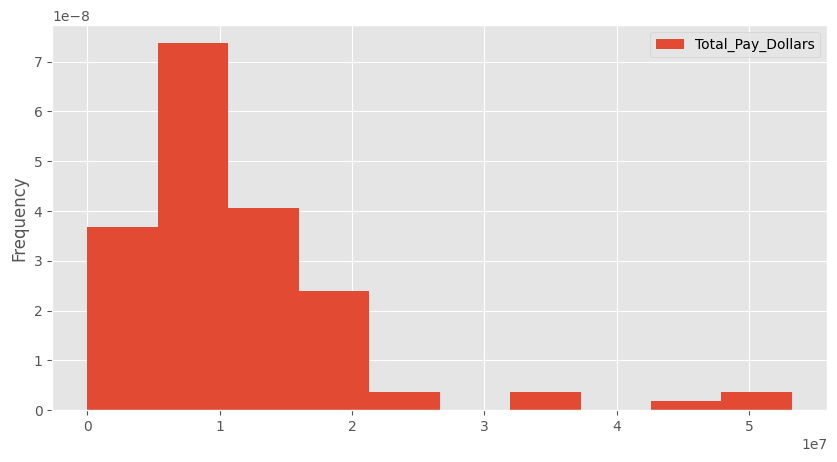

In [ ]:
# Descomente e execute!
compensation.plot(
    kind = 'hist',
    y = 'Total_Pay_Dollars',
    density = True,
    bins = 10,
    ec = 'w'
);

Analisando o histograma acima, vemos que nossas suspeitas estavam corretas: existe concentração de renda até nos salários dos CEOs mais bem pagos!

Aqui, a renda mediana é igual a:

In [ ]:
## Descomente e execute!
compensation.get('Total_Pay_Dollars').median()

9910000.0

... e a média é:

In [ ]:
# Descomente e execute!
compensation.get('Total_Pay_Dollars').mean()

np.float64(11445294.11764706)

Conforme mencionado acima, uma diferença positiva entre média e mediana também é evidência de assimetria à direita. 👍

#### **Pergunta 4.2.**

Na célula de código abaixo, descubra quantos CEOs ganharam mais de 30 milhões de dólares (pouco menos de 3 vezes a média e pouco mais de 3 vezes a mediana) em 2015.

In [ ]:
num_ceos_more_than_30_million = compensation.query('Total_Pay_Dollars > 30000000').shape[0]
num_ceos_more_than_30_million

5

# Linha de chegada 🏁

Parabéns! Você concluiu o Laboratório 2 com sucesso 👏👏👏

Para enviar sua tarefa:

1. Selecione `Kernel -> Restart Kernel and Run All Cells` para garantir que você executou todas as células, incluindo as células de teste.
1. Leia o notebook do começo ao fim com cuidado para ter certeza de que está tudo bem e que todos os testes foram aprovados.
1. Baixe seu notebook usando `File -> Save and Export Notebook As -> HTML` e, em seguida, carregue seu notebook para o Moodle.